# Mammography cohort preparation

Study-level partitioning and bounding-box preparation for Suspicious Calcification localization. Other region-annotated findings form the non-target controls.


In [1]:
from __future__ import annotations

import ast
import hashlib
import json
import os
import sys
import time
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import pydicom
from IPython.display import display
from sklearn.model_selection import StratifiedKFold

In [ ]:
EXPECTED_PYTHON = Path(os.environ.get("MAMMO_PYTHON", "/home/azyqan/venvs/ml-torch/bin/python")).resolve()
assert Path(sys.executable).resolve() == EXPECTED_PYTHON

import os

_start = Path.cwd().resolve()
PROJECT_ROOT = next(
    candidate for candidate in (_start, *_start.parents)
    if (candidate / "notebooks").is_dir()
    and (candidate / "artifacts").is_dir()
    and (candidate / "dataset").is_dir()
)
DATASET_ROOT = Path(os.environ.get("MAMMO_DATA_ROOT", PROJECT_ROOT / "dataset")).expanduser().resolve()
WORK_DATA_ROOT = Path(os.environ.get("MAMMO_WORK_DATA_ROOT", PROJECT_ROOT / "dataset")).expanduser().resolve()
DICOM_ROOT = DATASET_ROOT / "images_dicom"
if not DICOM_ROOT.is_dir() and (DATASET_ROOT / "images").is_dir():
    DICOM_ROOT = DATASET_ROOT / "images"
ANNOTATIONS = DATASET_ROOT / "annotations"
if not ANNOTATIONS.is_dir():
    ANNOTATIONS = DATASET_ROOT
RAW_DIR = WORK_DATA_ROOT / "Raw"
PROCESSED_DIR = WORK_DATA_ROOT / "Processed"
CONFIG_DIR = PROJECT_ROOT / "dataset" / "protocol"
MODEL_DIR = Path(os.environ.get("MAMMO_MODEL_ROOT", WORK_DATA_ROOT / "checkpoints")).expanduser().resolve()
COHORT_TABLES = PROJECT_ROOT / "dataset"
EDA_TABLES = PROJECT_ROOT / "artifacts" / "eda"
MODEL_TABLES = PROJECT_ROOT / "artifacts" / "models"
FIGURE_ROOT = PROJECT_ROOT / "figures"
FIGURE_INDEX = json.loads((FIGURE_ROOT / "index.json").read_text(encoding="utf-8"))
FIGURE_PATHS = {item["source"]: item["path"] for item in FIGURE_INDEX}

def resolve_figure(relative_path: str) -> Path:
    return PROJECT_ROOT / FIGURE_PATHS.get(relative_path, relative_path)

def protocol_table(name: str) -> Path:
    if name in ["bcrf_checkpoint_lineage.csv","bcrf_deployment_lineage.csv","bcrf_freeze_manifest.csv","frozen_evaluation_input_lineage.csv"]:
        return CONFIG_DIR / name
    return MODEL_TABLES / name

def resolve_dicom(relative_path: str) -> Path:
    name = Path(relative_path).name
    direct = DICOM_ROOT / name
    if direct.is_file():
        return direct
    candidates = list(DICOM_ROOT.rglob(name))
    if len(candidates) != 1:
        raise FileNotFoundError(f"Expected one DICOM for {name}; found {len(candidates)}")
    return candidates[0]

def legacy_relative_path(path: Path) -> str:
    if path.name in ["bcrf_checkpoint_lineage.csv", "bcrf_deployment_lineage.csv", "bcrf_freeze_manifest.csv", "frozen_evaluation_input_lineage.csv"]:
        return "Tables/Models/" + path.name
    if path.is_relative_to(MODEL_DIR):
        return "Models/" + str(path.relative_to(MODEL_DIR))
    if path.is_relative_to(WORK_DATA_ROOT / "Raw"):
        return "Data/Raw/" + str(path.relative_to(WORK_DATA_ROOT / "Raw"))
    if path.is_relative_to(PROCESSED_DIR):
        return "Data/Processed/" + str(path.relative_to(PROCESSED_DIR))
    if path.is_relative_to(CONFIG_DIR):
        return "Config/" + str(path.relative_to(CONFIG_DIR))
    if path.is_relative_to(MODEL_TABLES):
        return "Tables/Models/" + str(path.relative_to(MODEL_TABLES))
    return str(path.relative_to(PROJECT_ROOT))


In [3]:
PATHS = {
    "finding": ANNOTATIONS / "finding_annotations.csv",
    "breast": ANNOTATIONS / "breast-level_annotations.csv",
    "metadata": ANNOTATIONS / "metadata.csv",
    "source_hashes": DATASET_ROOT / "SOURCE_SHA256SUMS.txt",
    "sample": RAW_DIR / "immutable_sample_manifest.csv",
    "acquisition": RAW_DIR / "immutable_acquisition_manifest.csv",
    "splits": WORK_DATA_ROOT / "Splits" / "split_assignments.csv",
    "protocol": CONFIG_DIR / "split_protocol.json",
    "summary": COHORT_TABLES / "dataset_summary.csv",
    "provenance": CONFIG_DIR / "source_annotation_hashes.csv",
    "figure": FIGURE_ROOT / "S1_available_image_scope.png",
    "figure_pdf": FIGURE_ROOT / "S1_available_image_scope.pdf",
}
for path in PATHS.values():
    path.parent.mkdir(parents=True, exist_ok=True)

PROTOCOL_VERSION = "2.0.0"
TARGET_NAME = "Suspicious Calcification"
INNER_FOLDS = 5

In [4]:
times_font = Path("/mnt/c/Windows/Fonts/times.ttf")
if times_font.exists():
    font_manager.fontManager.addfont(times_font)

mpl.rcParams.update({
    "font.family": os.environ.get("MAMMO_FONT", "Times New Roman"),
    "font.size": 18,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "figure.titlesize": 20,
    "savefig.bbox": "tight",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})
pd.set_option("display.max_columns", 120)

In [5]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def write_frozen(path: Path, payload: bytes, allow_rebuild: bool) -> None:
    if path.exists() and path.read_bytes() != payload and not allow_rebuild:
        raise RuntimeError(f"Frozen artifact would change: {path}")
    if not path.exists() or path.read_bytes() != payload:
        path.write_bytes(payload)


def write_frozen_csv(frame: pd.DataFrame, path: Path, allow_rebuild: bool) -> None:
    payload = frame.to_csv(index=False, lineterminator="\n").encode("utf-8")
    write_frozen(path, payload, allow_rebuild)

In [6]:
def parse_categories(value) -> list[str]:
    if not isinstance(value, str) or not value.strip():
        return []
    try:
        parsed = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return [value.strip()]
    values = parsed if isinstance(parsed, list) else [parsed]
    return [str(item).strip() for item in values]


def source_checksum_maps(path: Path):
    image_hashes, file_hashes = {}, {}
    for line in path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        digest, relative = line.split(maxsplit=1)
        relative = relative.lstrip("*")
        file_hashes[Path(relative).name] = digest
        if relative.endswith(".dicom"):
            image_hashes[Path(relative).stem] = digest
    return image_hashes, file_hashes


def mode_or_unknown(series: pd.Series) -> str:
    values = series.dropna().astype(str).str.strip()
    return values.mode().iloc[0] if len(values) else "Unknown"

In [7]:
finding = pd.read_csv(PATHS["finding"], low_memory=False)
breast = pd.read_csv(PATHS["breast"], low_memory=False)
metadata = pd.read_csv(PATHS["metadata"], low_memory=False)

for frame in (finding, breast):
    for column in ("study_id", "series_id", "image_id"):
        frame[column] = frame[column].astype(str)

coordinate_columns = ["xmin", "ymin", "xmax", "ymax"]
for column in [*coordinate_columns, "height", "width"]:
    finding[column] = pd.to_numeric(finding[column], errors="coerce")

bbox_mask = finding[coordinate_columns].notna().all(axis=1)
bbox_full = finding.loc[bbox_mask].copy()
no_bbox = finding.loc[~bbox_mask].copy()

dicom_paths = sorted(DICOM_ROOT.rglob("*.dicom"))
local_ids = {path.stem for path in dicom_paths}
local_breast = breast.loc[breast.image_id.isin(local_ids)].copy()
local_findings = bbox_full.loc[bbox_full.image_id.isin(local_ids)].copy()

In [8]:
local_findings["categories"] = local_findings.finding_categories.map(parse_categories)
local_findings["is_target"] = local_findings.categories.map(
    lambda values: any(item.casefold() == TARGET_NAME.casefold() for item in values)
)

scope_summary = pd.DataFrame([
    ["annotation_universe", breast.image_id.nunique(), breast.study_id.nunique(),
     bbox_full.image_id.nunique(), len(bbox_full), len(no_bbox)],
    ["local_DICOM_cohort", len(local_ids), local_breast.study_id.nunique(),
     local_findings.image_id.nunique(), len(local_findings), 0],
    ["local_target", local_findings.loc[local_findings.is_target, "image_id"].nunique(),
     local_findings.loc[local_findings.is_target, "study_id"].nunique(),
     local_findings.loc[local_findings.is_target, "image_id"].nunique(),
     int(local_findings.is_target.sum()), np.nan],
], columns=["scope", "images", "studies", "bbox_images", "bbox_instances", "no_bbox_images"])

assert (len(local_ids), len(bbox_full), len(no_bbox)) == (1622, 2253, 18232)
assert (int(local_findings.is_target.sum()), local_findings.loc[local_findings.is_target, "image_id"].nunique()) == (499, 402)
display(scope_summary)

,scope,images,studies,bbox_images,bbox_instances,no_bbox_images
0,annotation_universe,20000,5000,1768,2253,18232.0
1,local_DICOM_cohort,1622,885,1622,2088,0.0
2,local_target,402,207,402,499,NaN


In [ ]:
try:
    existing_version = json.loads(PATHS["protocol"].read_text(encoding="utf-8")).get("protocol_version")
except Exception:
    existing_version = None
allow_rebuild = existing_version is None
if existing_version not in (None, PROTOCOL_VERSION, "3.0.0"):
    raise ValueError("Unsupported existing split protocol")

image_source_hashes, expected_file_hashes = source_checksum_maps(PATHS["source_hashes"])
provenance_rows = []
for key in ("finding", "breast", "metadata", "source_hashes"):
    path = PATHS[key]
    actual = sha256_file(path)
    expected = expected_file_hashes.get(path.name, "")
    provenance_rows.append({
        "file": path.name,
        "actual_sha256": actual,
        "source_manifest_sha256": expected,
        "matches_source_manifest": bool(expected) and actual.casefold() == expected.casefold(),
    })

provenance = pd.DataFrame(provenance_rows)


In [10]:
def first_value(value):
    try:
        if not isinstance(value, (str, bytes)) and hasattr(value, "__len__"):
            return value[0]
    except Exception:
        pass
    return value


def dicom_record(path: Path, expected_sha256: str) -> dict:
    ds = pydicom.dcmread(path)
    spacing = getattr(ds, "ImagerPixelSpacing", getattr(ds, "PixelSpacing", None))
    actual_sha256 = sha256_file(path)
    return {
        "image_id": path.stem,
        "study_id_dicom": str(getattr(ds, "StudyInstanceUID", "")),
        "series_id_dicom": str(getattr(ds, "SeriesInstanceUID", "")),
        "patient_id_available": bool(str(getattr(ds, "PatientID", "")).strip()),
        "rows": int(ds.Rows), "columns": int(ds.Columns),
        "bits_allocated": int(getattr(ds, "BitsAllocated", 0)),
        "bits_stored": int(getattr(ds, "BitsStored", 0)),
        "photometric_interpretation": str(getattr(ds, "PhotometricInterpretation", "")),
        "rescale_type": str(getattr(ds, "RescaleType", "")),
        "window_center": str(first_value(getattr(ds, "WindowCenter", ""))),
        "window_width": str(first_value(getattr(ds, "WindowWidth", ""))),
        "voi_lut_sequence_present": hasattr(ds, "VOILUTSequence"),
        "pixel_padding_value": str(getattr(ds, "PixelPaddingValue", "")),
        "pixel_padding_range_limit": str(getattr(ds, "PixelPaddingRangeLimit", "")),
        "manufacturer": str(getattr(ds, "Manufacturer", "")),
        "manufacturer_model": str(getattr(ds, "ManufacturerModelName", "")),
        "imager_pixel_spacing": "" if spacing is None else "|".join(map(str, spacing)),
        "file_size_bytes": int(path.stat().st_size),
        "actual_sha256": actual_sha256,
        "pixel_data_sha256": hashlib.sha256(bytes(ds.PixelData)).hexdigest(),
        "source_sha256": expected_sha256,
        "checksum_matches_source": actual_sha256.casefold() == expected_sha256.casefold(),
    }

In [11]:
pydicom.config.settings.reading_validation_mode = pydicom.config.IGNORE
required_acquisition = {"image_id", "actual_sha256", "pixel_data_sha256", "checksum_matches_source"}
reuse_acquisition = False
if PATHS["acquisition"].exists():
    cached = pd.read_csv(PATHS["acquisition"], low_memory=False)
    reuse_acquisition = (
        required_acquisition.issubset(cached.columns)
        and set(cached.image_id.astype(str)) == local_ids
        and cached[["actual_sha256", "pixel_data_sha256"]].notna().all().all()
    )

if reuse_acquisition:
    acquisition = cached.sort_values("image_id").reset_index(drop=True)
    print("Verified acquisition cache reused")
else:
    records, started = [], time.time()
    for index, path in enumerate(dicom_paths, 1):
        records.append(dicom_record(path, image_source_hashes[path.stem]))
        if index % 250 == 0 or index == len(dicom_paths):
            print(f"DICOM {index}/{len(dicom_paths)} | {time.time()-started:.1f} s", flush=True)
    acquisition = pd.DataFrame(records).sort_values("image_id").reset_index(drop=True)
    write_frozen_csv(acquisition, PATHS["acquisition"], allow_rebuild)

assert acquisition.image_id.nunique() == 1622
assert acquisition.actual_sha256.nunique() == 1622
assert acquisition.pixel_data_sha256.nunique() == 1622
assert acquisition.checksum_matches_source.astype(bool).all()
assert not acquisition.patient_id_available.astype(bool).any()


In [12]:
local_qc = local_findings.copy()
local_qc["xmin_clipped"] = local_qc.xmin.clip(lower=0)
local_qc["ymin_clipped"] = local_qc.ymin.clip(lower=0)
local_qc["xmax_clipped"] = np.minimum(local_qc.xmax, local_qc.width)
local_qc["ymax_clipped"] = np.minimum(local_qc.ymax, local_qc.height)
local_qc["bbox_was_clipped"] = (
    ~np.isclose(local_qc.xmin, local_qc.xmin_clipped)
    | ~np.isclose(local_qc.ymin, local_qc.ymin_clipped)
    | ~np.isclose(local_qc.xmax, local_qc.xmax_clipped)
    | ~np.isclose(local_qc.ymax, local_qc.ymax_clipped)
)
local_qc["bbox_valid"] = (
    (local_qc.xmax_clipped > local_qc.xmin_clipped)
    & (local_qc.ymax_clipped > local_qc.ymin_clipped)
)
invalid_local_boxes = int((~local_qc.bbox_valid).sum())
local_qc = local_qc.loc[local_qc.bbox_valid].copy()
target_findings = local_qc.loc[local_qc.is_target].copy()

bbox_qc = pd.DataFrame({
    "measure": ["all_local_boxes", "invalid_boxes", "clipped_boxes", "target_boxes", "clipped_target_boxes"],
    "value": [len(local_findings), invalid_local_boxes, int(local_qc.bbox_was_clipped.sum()), len(target_findings), int(target_findings.bbox_was_clipped.sum())],
})
display(bbox_qc)

,measure,value
0,all_local_boxes,2088
1,invalid_boxes,0
2,clipped_boxes,26
3,target_boxes,499
4,clipped_target_boxes,2


In [13]:
box_records = {}
for image_id, group in target_findings.groupby("image_id", sort=False):
    box_records[image_id] = [
        {
            "xmin": float(row.xmin_clipped), "ymin": float(row.ymin_clipped),
            "xmax": float(row.xmax_clipped), "ymax": float(row.ymax_clipped),
            "bbox_was_clipped": bool(row.bbox_was_clipped),
        }
        for row in group.itertuples()
    ]

category_records = {}
for image_id, group in local_qc.groupby("image_id", sort=False):
    category_records[image_id] = sorted({item for values in group.categories for item in values})

sample = local_breast.drop_duplicates("image_id").rename(columns={"split": "source_split"}).copy()
sample["source_split"] = sample.source_split.astype(str).str.lower().str.strip()
sample["sample_id"] = sample.image_id
sample["group_id"] = sample.study_id
sample["label"] = sample.image_id.isin(box_records).astype(int)
sample["control_definition"] = np.where(sample.label.eq(1), "target_positive", "other_annotated_finding")
sample["finding_categories"] = sample.image_id.map(lambda x: "|".join(category_records.get(x, [])))
sample["n_boxes"] = sample.image_id.map(lambda x: len(box_records.get(x, [])))
sample["n_clipped_boxes"] = sample.image_id.map(lambda x: sum(int(b["bbox_was_clipped"]) for b in box_records.get(x, [])))
sample["boxes_xyxy_json"] = sample.image_id.map(lambda x: json.dumps(box_records.get(x, []), separators=(",", ":")))
sample = sample.merge(acquisition, on="image_id", how="left", validate="one_to_one")

assert (len(sample), int(sample.label.sum()), int(sample.n_boxes.sum())) == (1622, 402, 499)


In [14]:
def study_frame(images: pd.DataFrame) -> pd.DataFrame:
    return images.groupby("study_id", as_index=False).agg(
        study_target=("label", "max"),
        positive_images=("label", "sum"),
        target_boxes=("n_boxes", "sum"),
        images=("image_id", "size"),
        manufacturer=("manufacturer", mode_or_unknown),
        density=("breast_density", mode_or_unknown),
    )


def first_fold(studies: pd.DataFrame, n_splits: int, seed: int) -> set[str]:
    splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    _, held = next(splitter.split(studies, studies.study_target))
    return set(studies.iloc[held].study_id)


def candidate_partitions(studies: pd.DataFrame, seed: int):
    locked = first_fold(studies, 7, seed)
    remaining = studies.loc[~studies.study_id.isin(locked)]
    validation = first_fold(remaining, 6, seed + 1)
    remaining = remaining.loc[~remaining.study_id.isin(validation)]
    calibration = first_fold(remaining, 5, seed + 2)
    training = set(remaining.study_id) - calibration
    return {"train": training, "validation": validation, "calibration": calibration, "locked_test": locked}

In [15]:
def balance_score(studies: pd.DataFrame, partitions: dict[str, set[str]]) -> float:
    working = studies.copy()
    working["vendor"] = working.manufacturer.where(
        working.manufacturer.isin(["SIEMENS", "Planmed", "IMS s.r.l."]), "Other"
    )
    deviations = []
    for study_ids in partitions.values():
        part = working.loc[working.study_id.isin(study_ids)]
        for column in ("study_target", "positive_images", "target_boxes", "images"):
            scale = max(float(working[column].std(ddof=0)), 1.0)
            deviations.append(abs(float(part[column].mean() - working[column].mean())) / scale)
        for column in ("vendor", "density"):
            for level in working[column].astype(str).unique():
                overall_rate = working[column].astype(str).eq(level).mean()
                part_rate = part[column].astype(str).eq(level).mean()
                deviations.append(abs(float(part_rate - overall_rate)))
    return max(deviations)

In [16]:
source_training = sample.loc[sample.source_split.eq("training")].copy()
source_training_studies = study_frame(source_training)
seed_scores = []
for seed in range(512):
    partitions = candidate_partitions(source_training_studies, seed)
    seed_scores.append((balance_score(source_training_studies, partitions), seed))

best_score, split_seed = min(seed_scores)
partitions = candidate_partitions(source_training_studies, split_seed)
study_to_split = {
    study_id: split_name
    for split_name, study_ids in partitions.items()
    for study_id in study_ids
}
study_to_split.update({
    study_id: "secondary_source_test"
    for study_id in sample.loc[sample.source_split.eq("test"), "study_id"].unique()
})
sample["split"] = sample.study_id.map(study_to_split)

assert sample.split.notna().all()
assert sample.groupby("study_id").split.nunique().max() == 1
print(f"Split seed={split_seed}; balance score={best_score:.4f}")

In [17]:
train_studies = study_frame(sample.loc[sample.split.eq("train")])
inner_splitter = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=split_seed + 3)
inner_study_fold = {}
for fold, (_, held) in enumerate(inner_splitter.split(train_studies, train_studies.study_target)):
    inner_study_fold.update({study_id: fold for study_id in train_studies.iloc[held].study_id})

sample["inner_fold"] = sample.study_id.map(inner_study_fold).fillna(-1).astype(int)
assignments = sample[["image_id", "study_id", "source_split", "split", "inner_fold", "label"]].copy()
assignments["split_seed"] = split_seed
assignments = assignments.sort_values("image_id").reset_index(drop=True)

split_summary = sample.groupby("split", as_index=False).agg(
    images=("image_id", "nunique"),
    studies=("study_id", "nunique"),
    target_positive_images=("label", "sum"),
    target_boxes=("n_boxes", "sum"),
    clipped_target_boxes=("n_clipped_boxes", "sum"),
)
split_summary["target_prevalence"] = split_summary.target_positive_images / split_summary.images

assert sample.groupby("study_id").split.nunique().max() == 1
assert set(sample.loc[sample.split.eq("train"), "inner_fold"]) == set(range(INNER_FOLDS))
assert (sample.loc[~sample.split.eq("train"), "inner_fold"] == -1).all()
display(split_summary)

,split,images,studies,target_positive_images,target_boxes,clipped_target_boxes,target_prevalence
0,calibration,183,101,40,60,0,0.218579
1,locked_test,183,101,44,57,0,0.240437
2,secondary_source_test,329,181,99,109,1,0.300912
3,train,745,401,177,219,0,0.237584
4,validation,182,101,42,54,1,0.230769


In [18]:
def dicom_header_enrichment(path: Path) -> dict:
    ds = pydicom.dcmread(path, stop_before_pixels=True)
    return {
        "image_id": path.stem,
        "modality": str(getattr(ds, "Modality", "")),
        "presentation_intent": str(getattr(ds, "PresentationIntentType", "")),
        "rescale_slope": float(getattr(ds, "RescaleSlope", 1.0)),
        "rescale_intercept": float(getattr(ds, "RescaleIntercept", 0.0)),
        "voi_lut_function": str(getattr(ds, "VOILUTFunction", "")),
        "presentation_lut_shape": str(getattr(ds, "PresentationLUTShape", "")),
        "pixel_intensity_relationship": str(getattr(ds, "PixelIntensityRelationship", "")),
        "pixel_intensity_relationship_sign": str(getattr(ds, "PixelIntensityRelationshipSign", "")),
        "view_position_dicom": str(getattr(ds, "ViewPosition", "")),
        "laterality_dicom": str(getattr(ds, "ImageLaterality", "")),
    }

In [19]:
required_header_columns = {"modality", "presentation_intent", "rescale_slope", "rescale_intercept"}
if not required_header_columns.issubset(acquisition.columns):
    enrichment = pd.DataFrame([dicom_header_enrichment(path) for path in dicom_paths])
    acquisition = acquisition.merge(enrichment, on="image_id", how="left", validate="one_to_one")
    write_frozen_csv(acquisition.sort_values("image_id"), PATHS["acquisition"], allow_rebuild)

sample = sample.drop(columns=[c for c in required_header_columns if c in sample.columns])
sample = sample.merge(
    acquisition[["image_id", *sorted(required_header_columns)]],
    on="image_id", how="left", validate="one_to_one",
)

header_summary = pd.DataFrame({
    "measure": ["VOI LUT Sequence", "Pixel Padding Range Limit", "MONOCHROME1", "MONOCHROME2"],
    "images": [
        int(acquisition.voi_lut_sequence_present.astype(bool).sum()),
        int(acquisition.pixel_padding_range_limit.fillna("").astype(str).str.len().gt(0).sum()),
        int(acquisition.photometric_interpretation.eq("MONOCHROME1").sum()),
        int(acquisition.photometric_interpretation.eq("MONOCHROME2").sum()),
    ],
})
display(header_summary)

,measure,images
0,VOI LUT Sequence,1181
1,Pixel Padding Range Limit,207
2,MONOCHROME1,234
3,MONOCHROME2,1388


In [20]:
sample["target_type"] = "suspicious_calcification_bbox_localization"
sample["relative_dicom_path"] = sample.image_id.map(lambda x: f"../dataset/images_dicom/{x}.dicom")
sample["duplicate_status"] = np.where(sample.actual_sha256.duplicated(keep=False), "duplicate_hash", "unique_hash")
sample["pixel_duplicate_status"] = np.where(sample.pixel_data_sha256.duplicated(keep=False), "duplicate_pixel_data", "unique_pixel_data")
sample["inclusion_status"] = "included"
sample["exclusion_reason"] = ""

manifest_columns = [
    "sample_id", "group_id", "image_id", "study_id", "series_id", "source_split", "split", "inner_fold",
    "label", "target_type", "control_definition", "finding_categories", "breast_birads", "breast_density",
    "laterality", "view_position", "height", "width", "n_boxes", "n_clipped_boxes", "boxes_xyxy_json",
    "manufacturer", "manufacturer_model", "modality", "presentation_intent", "photometric_interpretation",
    "bits_stored", "bits_allocated", "rescale_type", "imager_pixel_spacing", "relative_dicom_path",
    "actual_sha256", "pixel_data_sha256", "source_sha256", "checksum_matches_source",
    "duplicate_status", "pixel_duplicate_status", "inclusion_status", "exclusion_reason",
]
assert not [column for column in manifest_columns if column not in sample.columns]
sample_manifest = sample[manifest_columns].sort_values("sample_id").reset_index(drop=True)

write_frozen_csv(sample_manifest, PATHS["sample"], allow_rebuild)
write_frozen_csv(assignments, PATHS["splits"], allow_rebuild)
write_frozen_csv(split_summary, PATHS["summary"], allow_rebuild)
print("Sample manifest:", sample_manifest.shape)

In [ ]:
annotation_row = provenance.loc[provenance.file.eq("finding_annotations.csv")].iloc[0]
protocol = {
    "protocol_version": PROTOCOL_VERSION,
    "split_seed": int(split_seed),
    "seed_search": "0..511; pre-model target/vendor/density balance only",
    "sample_unit": "image/view",
    "independence_group": "study_id",
    "patient_level_independence_proven": False,
    "task": "Suspicious Calcification heatmap localization in a bbox-selected abnormal cohort",
    "controls": "other annotated findings; not normal mammograms",
    "reference": "radiologist bounding boxes; no pixel masks",
    "partitions": {
        "train": "fitting and 5 inner study folds",
        "validation": "architecture/loss/early-stopping and heatmap-threshold selection",
        "calibration": "uncertainty calibration after architecture and heatmap-threshold freeze",
        "locked_test": "single final batch after freeze",
        "secondary_source_test": "historically exposed secondary evaluation",
    },
    "standard_dicom_pipeline": [
        "stored pixels", "padding-range mask", "modality LUT", "VOI LUT/window",
        "presentation polarity", "valid-pixel normalization", "aspect-preserving resize/pad",
    ],
    "annotation_provenance": {
        "actual_sha256": annotation_row.actual_sha256,
        "source_manifest_match": bool(annotation_row.matches_source_manifest),
        "policy": "exact local snapshot frozen by explicit user instruction; mismatch disclosed",
    },
    "sample_manifest_sha256": sha256_file(PATHS["sample"]),
    "split_assignments_sha256": sha256_file(PATHS["splits"]),
}
if PATHS["protocol"].exists():
    frozen_protocol = json.loads(PATHS["protocol"].read_text(encoding="utf-8"))
    assert frozen_protocol["split_seed"] == int(split_seed)
    assert frozen_protocol["sample_manifest_sha256"] == sha256_file(PATHS["sample"])
    assert frozen_protocol["split_assignments_sha256"] == sha256_file(PATHS["splits"])
    protocol = frozen_protocol
else:
    write_frozen(
        PATHS["protocol"],
        (json.dumps(protocol, ensure_ascii=False, indent=2) + "\n").encode("utf-8"),
        allow_rebuild,
    )


In [22]:
train = sample_manifest.loc[sample_manifest.split.eq("train")].copy()
train_box_area = []
for row in train.loc[train.label.eq(1)].itertuples():
    for box in json.loads(row.boxes_xyxy_json):
        box_area = (box["xmax"] - box["xmin"]) * (box["ymax"] - box["ymin"])
        train_box_area.append(100.0 * box_area / (float(row.width) * float(row.height)))

plot_data = {
    "vendors": train.manufacturer.value_counts().sort_values(),
    "density": train.breast_density.astype(str).value_counts().sort_index(),
    "views": train.view_position.astype(str).value_counts().sort_values(),
    "box_area": np.asarray(train_box_area),
}
assert len(plot_data["box_area"]) == int(train.n_boxes.sum())


In [23]:
FIGURE_DIR = FIGURE_ROOT
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
figure_registry = []


def save_scientific_figure(fig: plt.Figure, stem: str) -> None:
    png_path = resolve_figure("Figures/EDA/" + stem + ".png")
    pdf_path = resolve_figure("Figures/EDA/" + stem + ".pdf")
    fig.savefig(png_path, dpi=350)
    fig.savefig(pdf_path)
    figure_registry.append({
        "figure_id": stem,
        "png_path": str(png_path.relative_to(PROJECT_ROOT)),
        "pdf_path": str(pdf_path.relative_to(PROJECT_ROOT)),
        "png_sha256": sha256_file(png_path),
        "pdf_sha256": sha256_file(pdf_path),
        "dpi": 350,
        "title_font_pt": 20,
        "other_text_pt": 18,
    })

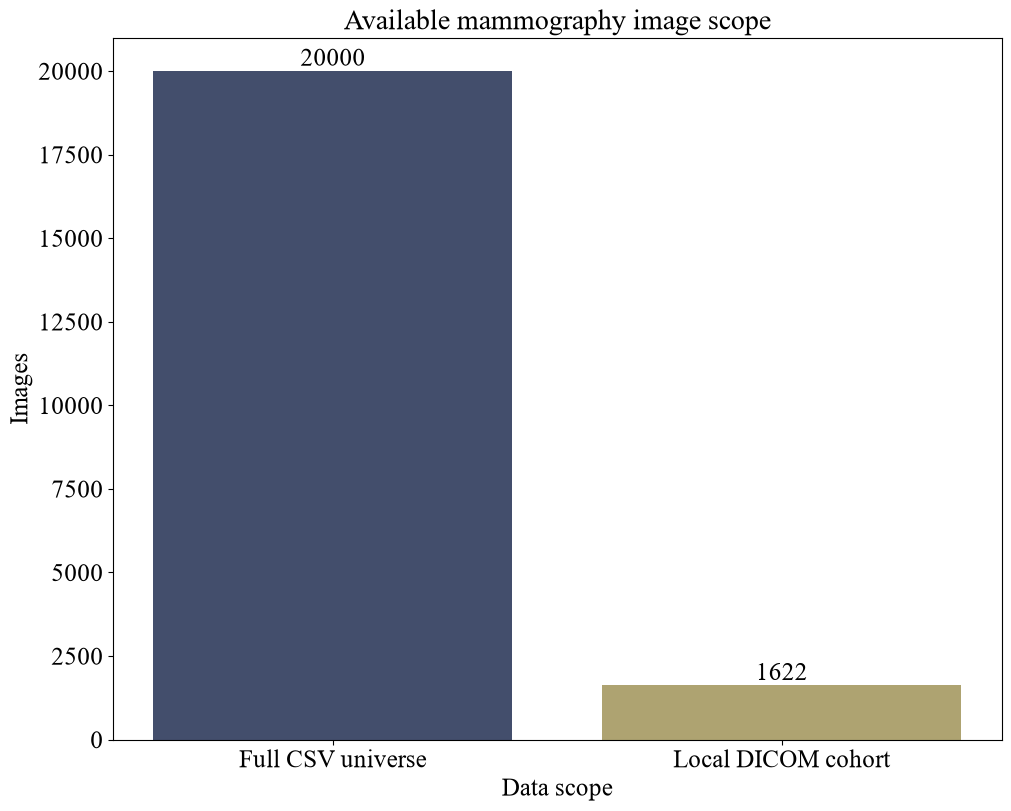

In [24]:
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
scope = scope_summary.set_index("scope")
values = [
    scope.loc["annotation_universe", "images"],
    scope.loc["local_DICOM_cohort", "images"],
]
bars = ax.bar(
    ["Full CSV universe", "Local DICOM cohort"],
    values,
    color=mpl.colormaps["cividis"]([0.25, 0.70]),
)
ax.set_title("Available mammography image scope", fontsize=20)
ax.set_xlabel("Data scope", fontsize=18)
ax.set_ylabel("Images", fontsize=18)
ax.bar_label(bars, fontsize=18)
save_scientific_figure(fig, "F01_available_image_scope")
plt.show()

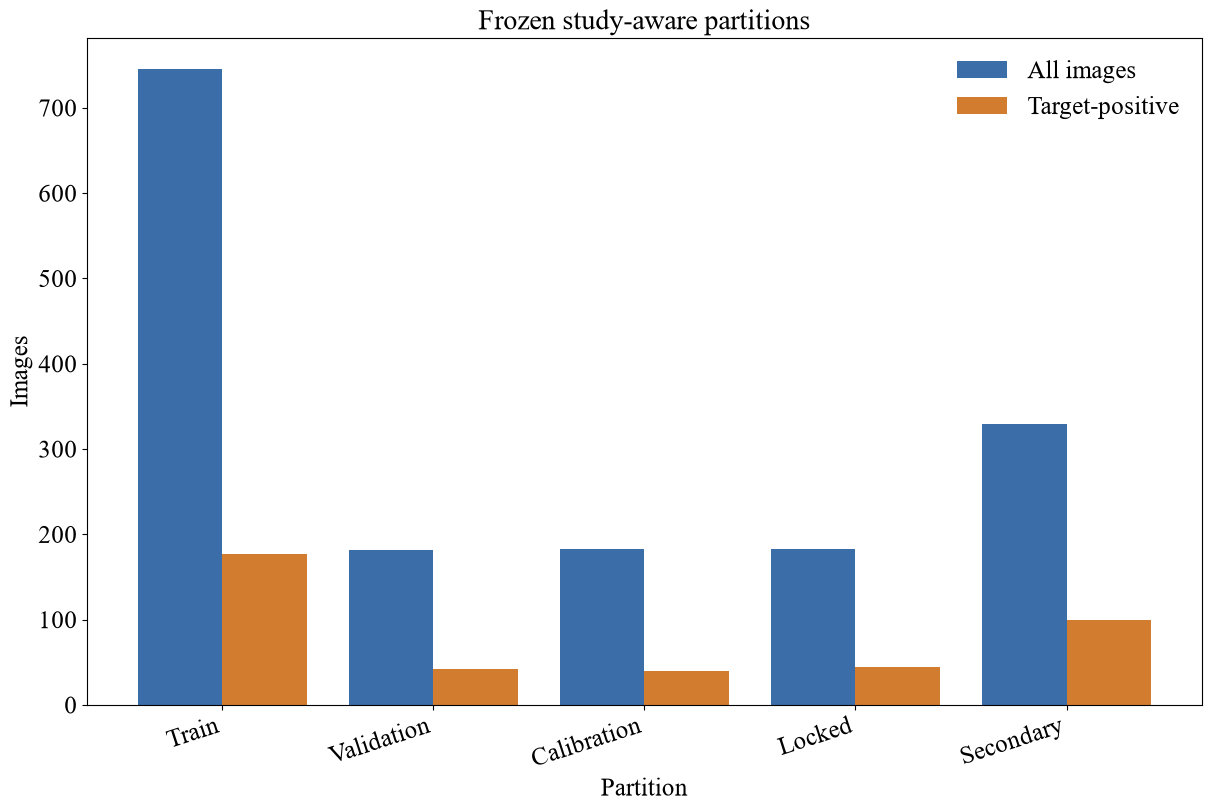

In [25]:
fig, ax = plt.subplots(figsize=(12, 8), constrained_layout=True)
ordered = split_summary.set_index("split").loc[
    ["train", "validation", "calibration", "locked_test", "secondary_source_test"]
]
x = np.arange(len(ordered))
ax.bar(x - 0.20, ordered.images, width=0.40, label="All images", color="#3B6EA8")
ax.bar(x + 0.20, ordered.target_positive_images, width=0.40, label="Target-positive", color="#D17C2F")
ax.set_xticks(x, ["Train", "Validation", "Calibration", "Locked", "Secondary"], rotation=18, ha="right")
ax.set_title("Frozen study-aware partitions", fontsize=20)
ax.set_xlabel("Partition", fontsize=18)
ax.set_ylabel("Images", fontsize=18)
ax.legend(frameon=False, loc="upper right")
save_scientific_figure(fig, "F02_frozen_partitions")
plt.show()

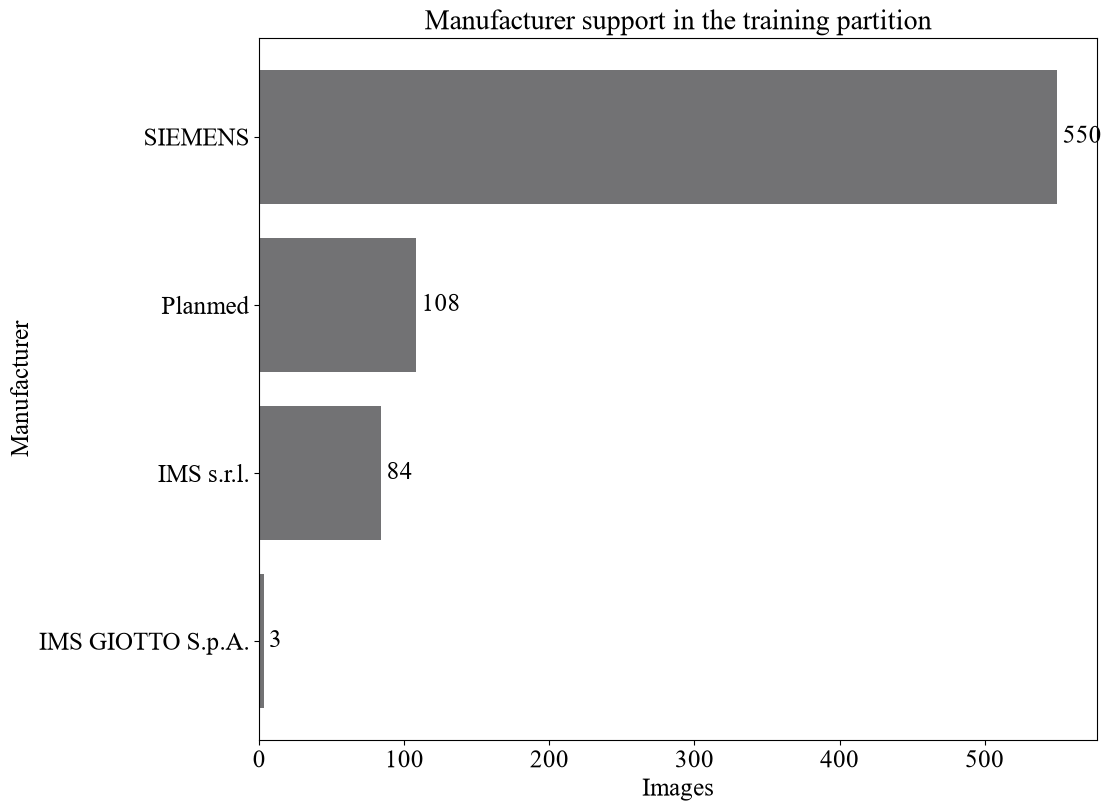

In [26]:
fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
vendors = plot_data["vendors"]
bars = ax.barh(vendors.index, vendors.values, color=mpl.colormaps["cividis"](0.45))
ax.set_title("Manufacturer support in the training partition", fontsize=20)
ax.set_xlabel("Images", fontsize=18)
ax.set_ylabel("Manufacturer", fontsize=18)
ax.bar_label(bars, fontsize=18, padding=4)
save_scientific_figure(fig, "F03_train_manufacturer_support")
plt.show()

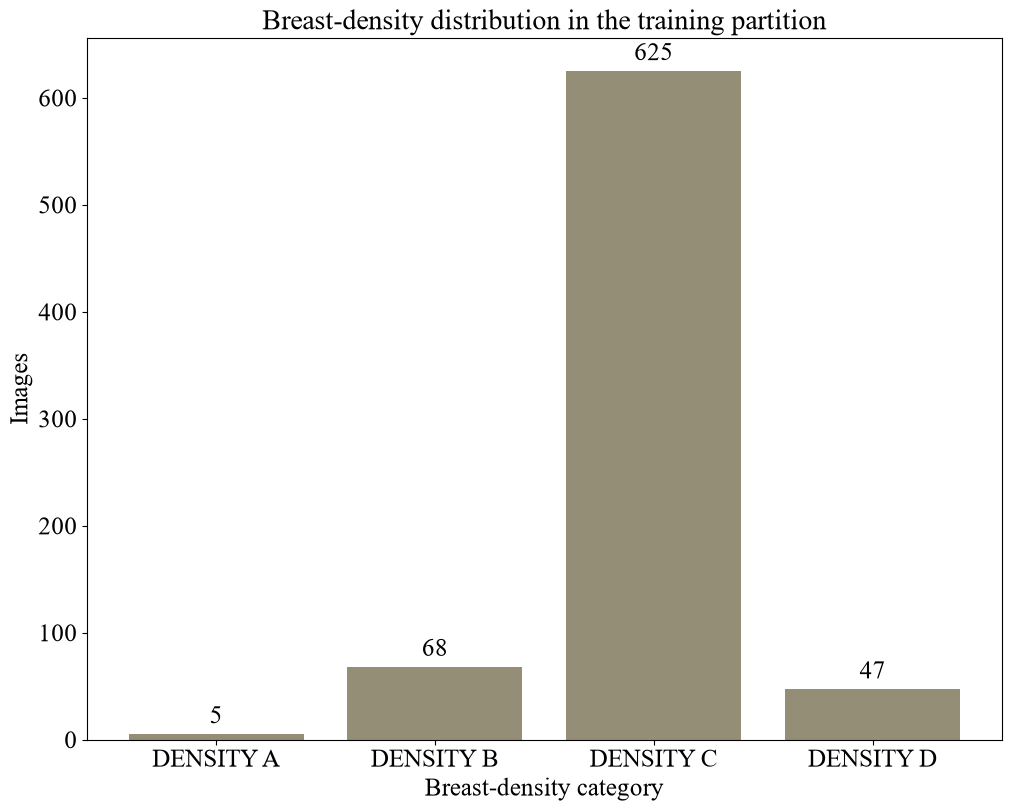

In [27]:
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
density = plot_data["density"]
bars = ax.bar(density.index, density.values, color=mpl.colormaps["cividis"](0.60))
ax.set_title("Breast-density distribution in the training partition", fontsize=20)
ax.set_xlabel("Breast-density category", fontsize=18)
ax.set_ylabel("Images", fontsize=18)
ax.bar_label(bars, fontsize=18, padding=4)
save_scientific_figure(fig, "F04_train_breast_density")
plt.show()

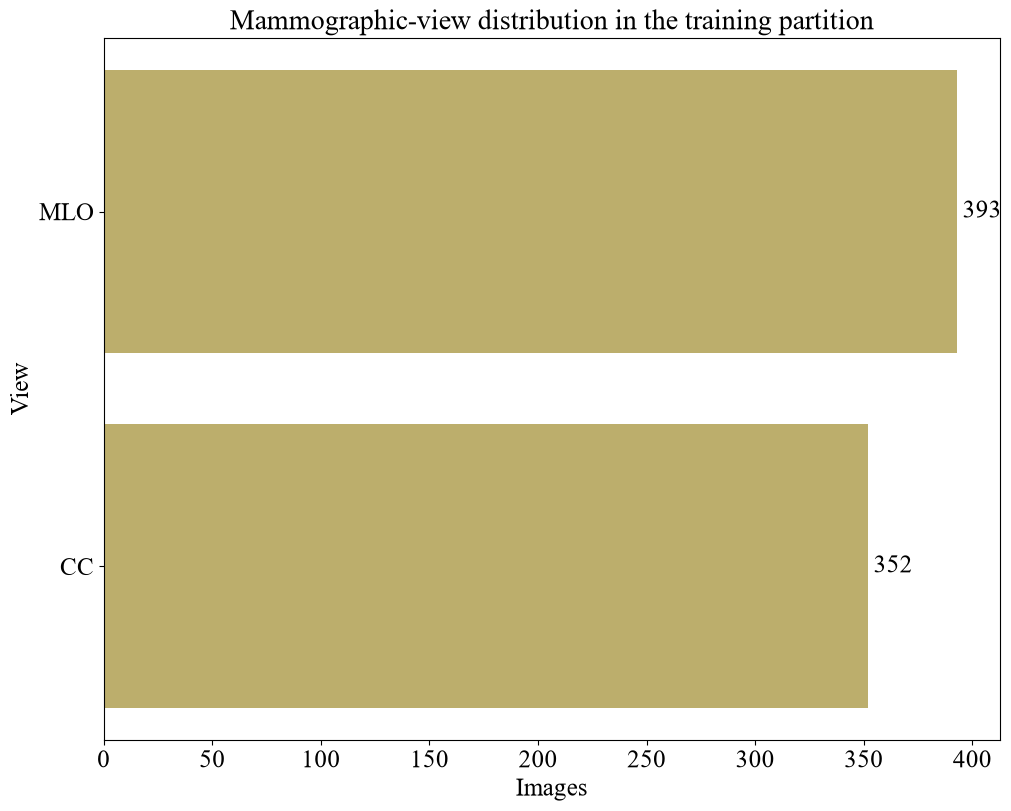

In [28]:
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
views = plot_data["views"]
bars = ax.barh(views.index, views.values, color=mpl.colormaps["cividis"](0.75))
ax.set_title("Mammographic-view distribution in the training partition", fontsize=20)
ax.set_xlabel("Images", fontsize=18)
ax.set_ylabel("View", fontsize=18)
ax.bar_label(bars, fontsize=18, padding=4)
save_scientific_figure(fig, "F05_train_view_distribution")
plt.show()

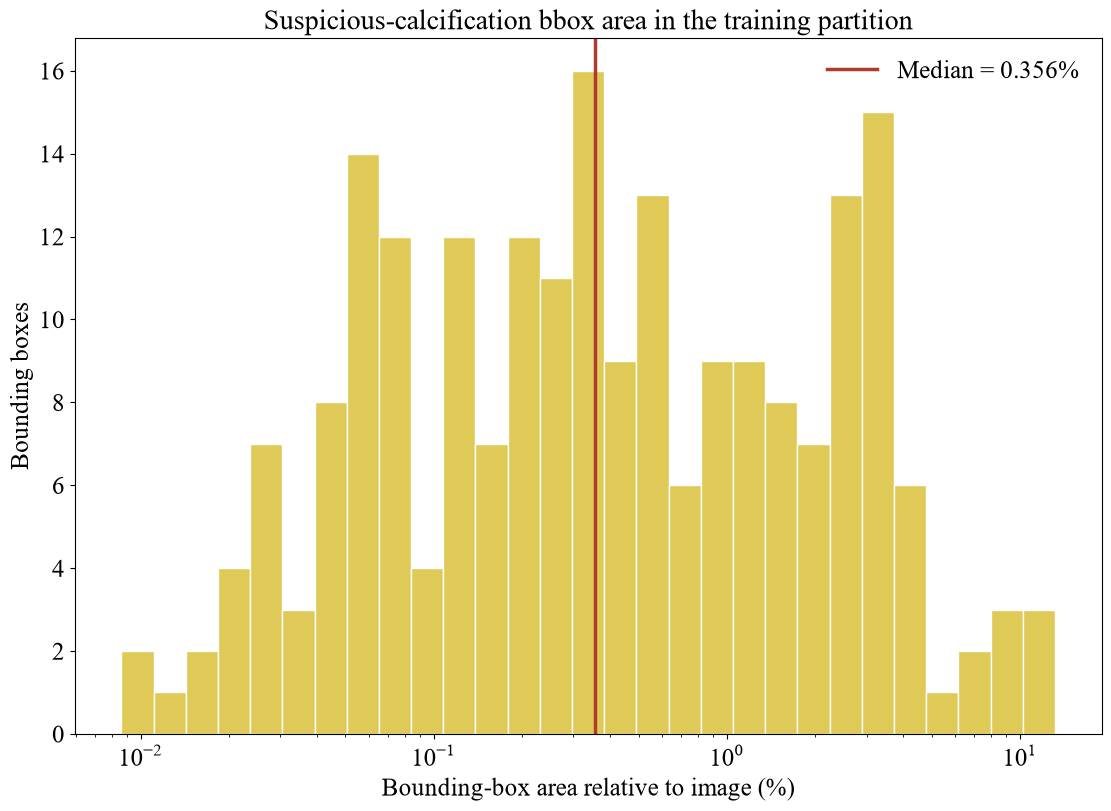

In [29]:
fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
area = plot_data["box_area"]
bins = np.geomspace(max(area.min(), 1e-4), area.max(), 30)
ax.hist(area, bins=bins, color=mpl.colormaps["cividis"](0.88), edgecolor="white")
median_area = float(np.median(area))
ax.axvline(median_area, color="#B03A2E", linewidth=2.5, label=f"Median = {median_area:.3f}%")
ax.set_xscale("log")
ax.set_title("Suspicious-calcification bbox area in the training partition", fontsize=20)
ax.set_xlabel("Bounding-box area relative to image (%)", fontsize=18)
ax.set_ylabel("Bounding boxes", fontsize=18)
ax.legend(frameon=False, loc="upper right")
save_scientific_figure(fig, "F06_train_target_bbox_area")
plt.show()

## External locked cohort

CBIS-DDSM Calc-Test is acquired from the official IDC release. Full mammograms are model inputs; ROI masks are reserved for deterministic external reference boxes.

In [ ]:
from io import StringIO
from pathlib import Path
import hashlib

import pandas as pd
import requests
from IPython.display import display
from idc_index import IDCClient

EXTERNAL_ROOT = RAW_DIR / "CBIS-DDSM_Calc-Test"
EXTERNAL_DICOM = EXTERNAL_ROOT / "dicom"
EXTERNAL_CSV = EXTERNAL_ROOT / "calc_case_description_test_set.csv"
EXTERNAL_SERIES = EXTERNAL_ROOT / "immutable_external_series_manifest.csv"
EXTERNAL_URL = (
    "https://wiki.cancerimagingarchive.net/download/attachments/"
    "22516629/calc_case_description_test_set.csv?api=v2"
)
EXTERNAL_DOI = "10.7937/K9/TCIA.2016.7O02S9CY"

DOWNLOAD_EXTERNAL_DATA = False

if DOWNLOAD_EXTERNAL_DATA:
    EXTERNAL_ROOT.mkdir(parents=True, exist_ok=True)
    response = requests.get(EXTERNAL_URL, timeout=60)
    response.raise_for_status()
    EXTERNAL_CSV.write_bytes(response.content)
    source_sha256 = hashlib.sha256(response.content).hexdigest()

    external_annotations = pd.read_csv(StringIO(response.text))
    path_columns = [
        "image file path",
        "cropped image file path",
        "ROI mask file path",
    ]
    for column in path_columns:
        external_annotations[column] = (
            external_annotations[column].astype(str).str.strip()
        )
        external_annotations[f"{column}_series_uid"] = (
            external_annotations[column].str.split("/").str[-2]
        )

    idc_client = IDCClient()
    idc_index = idc_client.sql_query(
        "SELECT * FROM index WHERE collection_id='cbis_ddsm'"
    )
    full_uids = sorted(
        external_annotations["image file path_series_uid"].unique()
    )
    roi_uids = sorted(
        external_annotations["ROI mask file path_series_uid"].unique()
    )

    assert external_annotations["patient_id"].nunique() == 151
    assert len(full_uids) == 284
    assert len(roi_uids) == 326
    assert set(full_uids + roi_uids).issubset(
        set(idc_index["SeriesInstanceUID"])
    )

    full_series = idc_index[
        idc_index["SeriesInstanceUID"].isin(full_uids)
    ].copy()
    full_series["data_role"] = "full_mammogram_input"
    roi_series = idc_index[
        idc_index["SeriesInstanceUID"].isin(roi_uids)
    ].copy()
    roi_series["data_role"] = "roi_crop_reference"

    external_series = pd.concat(
        [full_series, roi_series],
        ignore_index=True,
    ).sort_values(["data_role", "SeriesInstanceUID"])
    external_series["source_csv_sha256"] = source_sha256
    external_series["source_doi"] = EXTERNAL_DOI
    external_series.to_csv(EXTERNAL_SERIES, index=False)

    expected_instances = int(external_series["instanceCount"].sum())
    expected_size_gb = external_series["series_size_MB"].sum() / 1024
    downloaded_before = len(list(EXTERNAL_DICOM.rglob("*.dcm")))

    if downloaded_before < expected_instances:
        idc_client.download_dicom_series(
            external_series["SeriesInstanceUID"].tolist(),
            str(EXTERNAL_DICOM),
            quiet=True,
            show_progress_bar=False,
            use_s5cmd_sync=downloaded_before > 0,
            dirTemplate="%PatientID/%SeriesInstanceUID",
            source_bucket_location="aws",
        )

    downloaded_after = len(list(EXTERNAL_DICOM.rglob("*.dcm")))
    assert downloaded_after == expected_instances

